In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from PIL import Image

In [3]:
# Load an image
image = cv2.imread("image.jpg")

# OpenCV loads images in BGR order
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Detect edges
edges = cv2.Canny(gray, 100, 200)



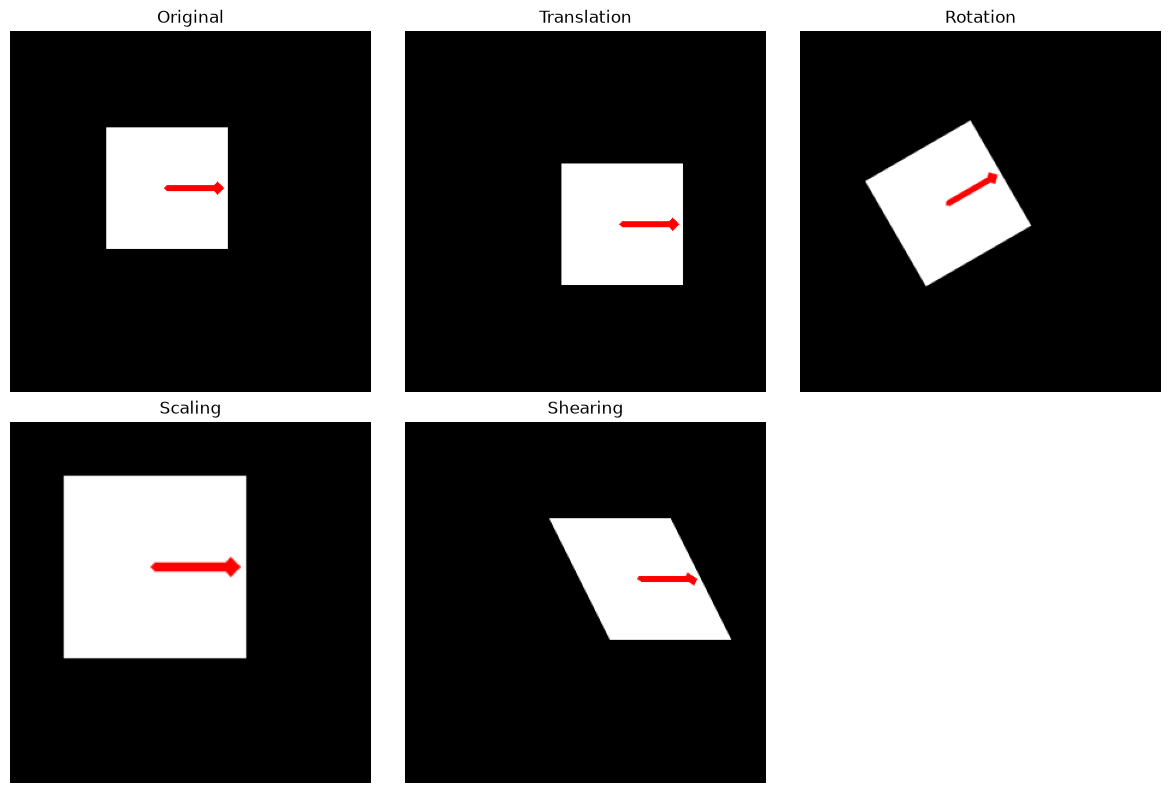

In [ ]:
#Affine Transformation
# 1. Create a blank image (height=300, width=300)
img = np.zeros((300, 300, 3), dtype=np.uint8) #=> 2D array x3 each for RGB

# Draw a white rectangle
cv2.rectangle(img, (80, 80), (180, 180), (255, 255, 255), -1)

# Draw a red arrow to help us see the direction
cv2.arrowedLine(img, (130, 130), (175, 130),
                (0, 0, 255), 3)

# Get the image dimensions
height, width = img.shape[:2]

# 2. Translation: move right 50 pixels and down 30 pixels
translation_matrix = np.float32([
    [1, 0, 50],
    [0, 1, 30]
])

translated = cv2.warpAffine(
    img, translation_matrix, (width, height)
)  # src, matrix(2x3), size(output size)

# 3. Rotation: rotate 30 degrees around the image center
center = (width // 2, height // 2)

rotation_matrix = cv2.getRotationMatrix2D(
    center, 30, 1.0
)

rotated = cv2.warpAffine(
    img, rotation_matrix, (width, height)
)

# 4. Scaling: enlarge the image by 1.5 times
scaling_matrix = cv2.getRotationMatrix2D(
    center, 0, 1.5
)

scaled = cv2.warpAffine(
    img, scaling_matrix, (width, height)
)

# 5. Shearing: slant the image horizontally
shear_matrix = np.float32([
    [1, 0.5, 0],
    [0, 1, 0]
])

sheared = cv2.warpAffine(
    img, shear_matrix, (width, height)
)

# Display all results
images = [
    ("Original", img),
    ("Translation", translated),
    ("Rotation", rotated),
    ("Scaling", scaled),
    ("Shearing", sheared)
]

plt.figure(figsize=(12, 8))

for i, (title, image) in enumerate(images):
    plt.subplot(2, 3, i + 1)

    # OpenCV uses BGR, so convert to RGB for Matplotlib
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

(np.float64(-0.5), np.float64(319.5), np.float64(319.5), np.float64(-0.5))

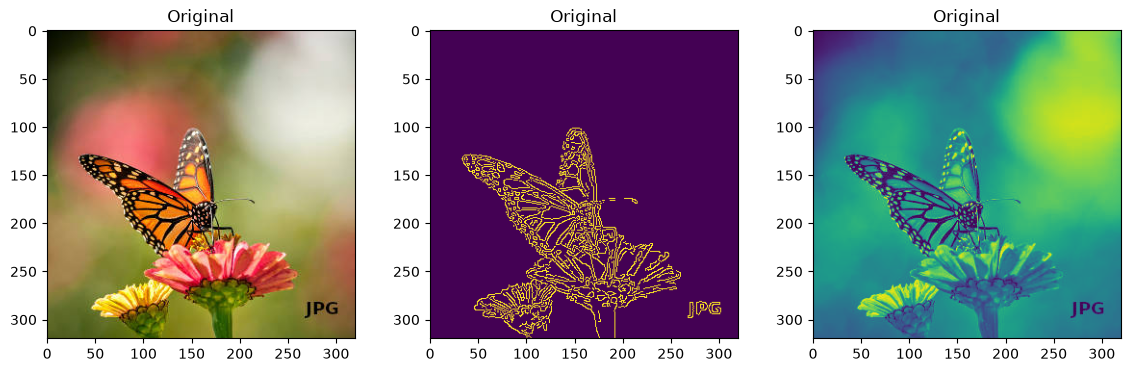

In [4]:
# Display results
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("on")

plt.subplot(1, 3, 2)
plt.imshow(edges)
plt.title("Original")
plt.axis("on")

plt.subplot(1, 3, 3)
plt.imshow(gray)
plt.title("Original")
plt.axis("on")